In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
df=pd.read_csv('./Retail_Sales_Easy_Project.csv')
print(df.head())



  Transaction_ID        Date Product_ID                Product_Name  \
0  TRX-2025-1001  2025-03-04       P011           Multiport USB Hub   
1  TRX-2025-1002  2025-06-01       P004        Bluetooth Headphones   
2  TRX-2025-1003  2025-03-01       P007   Gel Pen Pack (Pack of 10)   
3  TRX-2025-1004  2025-02-26       P009  Waterproof Laptop Backpack   
4  TRX-2025-1005  2025-03-29       P008      Ergonomic Laptop Stand   

      Category  Unit_Price  Quantity  Total_Revenue  Cost_Price  \
0  Electronics        1100         2           2200        1400   
1  Electronics        2200         3           6600        4200   
2   Stationery         250         1            250         120   
3  Accessories        1800         1           1800        1100   
4  Accessories        1250         5           6250        3750   

  Payment_Method   Store_City  Sales_Channel  
0     Debit Card      Chennai     Mobile App  
1            UPI  Tirunelveli  Store Walk-in  
2    Credit Card      Chennai

In [12]:
excel_df = pd.read_excel("Retail_Sales_Easy_Project.xlsx", sheet_name="SalesData")
display(excel_df.tail(5))

,Transaction_ID,Date,Product_ID,Product_Name,Category,Unit_Price,Quantity,Total_Revenue,Cost_Price,Payment_Method,Store_City,Sales_Channel
795,TRX-2025-1796,2025-04-21,P007,Gel Pen Pack (Pack of 10),Stationery,250,7,1750,840,Cash,Trichy,Mobile App
796,TRX-2025-1797,2025-05-17,P006,Executive Diary & Pen Set,Stationery,450,1,450,220,UPI,Trichy,Mobile App
797,TRX-2025-1798,2025-06-29,P001,Smart Wireless Mouse,Electronics,650,2,1300,900,UPI,Tirunelveli,Mobile App
798,TRX-2025-1799,2025-06-25,P002,Mechanical Keyboard,Electronics,2400,6,14400,9600,Debit Card,Salem,Store Walk-in
799,TRX-2025-1800,2025-04-12,P005,USB-C Fast Charger,Electronics,850,2,1700,1000,Cash,Madurai,Online Website


In [19]:
display(df.sample(n=6, random_state=42))

,Transaction_ID,Date,Product_ID,Product_Name,Category,Unit_Price,Quantity,Total_Revenue,Cost_Price,Payment_Method,Store_City,Sales_Channel
696,TRX-2025-1697,2025-01-14,P010,Desk Organizer Tray,Stationery,550,5,2750,1500,Cash,Trichy,Store Walk-in
667,TRX-2025-1668,2025-03-10,P003,HD Webcam 1080p,Electronics,1850,5,9250,6000,Debit Card,Tirunelveli,Online Website
63,TRX-2025-1064,2025-03-27,P002,Mechanical Keyboard,Electronics,2400,7,16800,11200,UPI,Madurai,Store Walk-in
533,TRX-2025-1534,2025-01-24,P006,Executive Diary & Pen Set,Stationery,450,8,3600,1760,UPI,Trichy,Online Website
66,TRX-2025-1067,2025-05-30,P012,Spiral Ruled Notebooks (Set of 4),Stationery,380,3,1140,570,Debit Card,Salem,Store Walk-in
621,TRX-2025-1622,2025-03-24,P006,Executive Diary & Pen Set,Stationery,450,4,1800,880,Credit Card,Coimbatore,Online Website


In [20]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values in each column:")
print(df.isnull().sum())

Column names:
['Transaction_ID', 'Date', 'Product_ID', 'Product_Name', 'Category', 'Unit_Price', 'Quantity', 'Total_Revenue', 'Cost_Price', 'Payment_Method', 'Store_City', 'Sales_Channel']

Data types:
Transaction_ID      str
Date                str
Product_ID          str
Product_Name        str
Category            str
Unit_Price        int64
Quantity          int64
Total_Revenue     int64
Cost_Price        int64
Payment_Method      str
Store_City          str
Sales_Channel       str
dtype: object

Missing values in each column:
Transaction_ID    0
Date              0
Product_ID        0
Product_Name      0
Category          0
Unit_Price        0
Quantity          0
Total_Revenue     0
Cost_Price        0
Payment_Method    0
Store_City        0
Sales_Channel     0
dtype: int64


In [21]:
display(df.describe().loc[["count", "mean", "min", "max"]])

,Unit_Price,Quantity,Total_Revenue,Cost_Price
count,800.000,800.00000,800.000,800.0000
mean,1154.175,4.55125,5275.075,3275.8875
min,250.000,1.00000,250.000,120.0000
max,2400.000,8.00000,19200.000,12800.0000


In [22]:
rows, columns = df.shape
print("Total rows:", rows)
print("Total columns:", columns)

Total rows: 800
Total columns: 12


In [23]:
print(df.count())

Transaction_ID    800
Date              800
Product_ID        800
Product_Name      800
Category          800
Unit_Price        800
Quantity          800
Total_Revenue     800
Cost_Price        800
Payment_Method    800
Store_City        800
Sales_Channel     800
dtype: int64


In [24]:
revenue_array = df["Total_Revenue"].to_numpy()
print("Array:", revenue_array)
print("Data type:", revenue_array.dtype)
print("Length:", len(revenue_array))

Array: [ 2200  6600   250  1800  6250  2550   500  3040  9000  4400  9600  6600
  5500  3300  8750   450  1700  8800  2550  1750  2500 12950  4400   760
   900  3250  3400  1800 14400  1100  5400  9250  7200  6600  8800  7200
   380  9600  5400  8750  1500  2200  8800   750  2500  6600   250  6800
 11000   650  3600 15400   550  3300  5950   900  7200  9600  9000  9000
  4800  3400  5500 16800  9250  2660  1140  5400   450 14400  5550  1000
  5200  3400  2250 12600 12000 16800  1100  4550   500 12000  1250  7700
  2750  3400 10000  2200 11000  2600  1000  1000  1000  7200  6600  3750
 11000  2500  2700 15400  1750  2600  2000  1000  1250  3750   550  3750
 17600  1250  3900   650  7400 17600  1100  3250  1520  1900  3900 10800
  1500  9250  1250  5000  5200  2250  2600  7200  1300 11000 10800  3040
  9600 17600 11000  1950  2550  2750  1850  2000  9250  1000  5950   760
  2200  7200  4400  1900 11000  9600  2400 19200 14400  2280  2200 10000
  2500   900  6250 14400  1800  2600  1250 1

In [25]:
price_quantity_array = df[["Unit_Price", "Quantity"]].to_numpy()
print(price_quantity_array)
print("Array shape:", price_quantity_array.shape)

[[1100    2]
 [2200    3]
 [ 250    1]
 ...
 [ 650    2]
 [2400    6]
 [ 850    2]]
Array shape: (800, 2)


In [26]:
grand_total_revenue = np.sum(revenue_array)
print("Grand total revenue: ₹", grand_total_revenue)

Grand total revenue: ₹ 4220060


In [27]:
print("Mean revenue: ₹", np.mean(revenue_array))
print("Median revenue: ₹", np.median(revenue_array))

Mean revenue: ₹ 5275.075
Median revenue: ₹ 3600.0


In [28]:
print("Standard deviation:", np.std(revenue_array))
print("Variance:", np.var(revenue_array))

Standard deviation: 4488.204818674722
Variance: 20143982.494375


In [29]:
print("Lowest single-sale revenue: ₹", np.min(revenue_array))
print("Highest single-sale revenue: ₹", np.max(revenue_array))

Lowest single-sale revenue: ₹ 250
Highest single-sale revenue: ₹ 19200


In [30]:
print("Index of highest-revenue sale:", df["Total_Revenue"].idxmax())
print("Index of lowest-revenue sale:", df["Total_Revenue"].idxmin())

Index of highest-revenue sale: 151
Index of lowest-revenue sale: 2


In [31]:
df["Running_Total_Revenue"] = df["Total_Revenue"].cumsum()
display(df[["Date", "Total_Revenue", "Running_Total_Revenue"]].head(10))

,Date,Total_Revenue,Running_Total_Revenue
0,2025-03-04,2200,2200
1,2025-06-01,6600,8800
2,2025-03-01,250,9050
3,2025-02-26,1800,10850
4,2025-03-29,6250,17100
5,2025-01-24,2550,19650
6,2025-01-12,500,20150
7,2025-01-21,3040,23190
8,2025-05-28,9000,32190
9,2025-03-16,4400,36590


In [32]:
display(df.iloc[:10])

,Transaction_ID,Date,Product_ID,Product_Name,Category,Unit_Price,Quantity,Total_Revenue,Cost_Price,Payment_Method,Store_City,Sales_Channel,Running_Total_Revenue
0,TRX-2025-1001,2025-03-04,P011,Multiport USB Hub,Electronics,1100,2,2200,1400,Debit Card,Chennai,Mobile App,2200
1,TRX-2025-1002,2025-06-01,P004,Bluetooth Headphones,Electronics,2200,3,6600,4200,UPI,Tirunelveli,Store Walk-in,8800
2,TRX-2025-1003,2025-03-01,P007,Gel Pen Pack (Pack of 10),Stationery,250,1,250,120,Credit Card,Chennai,Store Walk-in,9050
3,TRX-2025-1004,2025-02-26,P009,Waterproof Laptop Backpack,Accessories,1800,1,1800,1100,Cash,Salem,Store Walk-in,10850
4,TRX-2025-1005,2025-03-29,P008,Ergonomic Laptop Stand,Accessories,1250,5,6250,3750,Cash,Chennai,Store Walk-in,17100
5,TRX-2025-1006,2025-01-24,P005,USB-C Fast Charger,Electronics,850,3,2550,1500,UPI,Coimbatore,Online Website,19650
6,TRX-2025-1007,2025-01-12,P007,Gel Pen Pack (Pack of 10),Stationery,250,2,500,240,Debit Card,Madurai,Online Website,20150
7,TRX-2025-1008,2025-01-21,P012,Spiral Ruled Notebooks (Set of 4),Stationery,380,8,3040,1520,Cash,Salem,Store Walk-in,23190
8,TRX-2025-1009,2025-05-28,P009,Waterproof Laptop Backpack,Accessories,1800,5,9000,5500,Debit Card,Tirunelveli,Mobile App,32190
9,TRX-2025-1010,2025-03-16,P004,Bluetooth Headphones,Electronics,2200,2,4400,2800,Credit Card,Chennai,Mobile App,36590


In [33]:
display(df.loc[100:120, ["Product_Name", "Total_Revenue", "Store_City"]])

,Product_Name,Total_Revenue,Store_City
100,Gel Pen Pack (Pack of 10),1750,Madurai
101,Smart Wireless Mouse,2600,Trichy
102,Gel Pen Pack (Pack of 10),2000,Chennai
103,Gel Pen Pack (Pack of 10),1000,Trichy
104,Ergonomic Laptop Stand,1250,Trichy
105,Ergonomic Laptop Stand,3750,Salem
106,Desk Organizer Tray,550,Chennai
107,Ergonomic Laptop Stand,3750,Chennai
108,Bluetooth Headphones,17600,Madurai
109,Gel Pen Pack (Pack of 10),1250,Chennai


In [34]:
electronics_sales = df[df["Category"] == "Electronics"]
display(electronics_sales)

,Transaction_ID,Date,Product_ID,Product_Name,Category,Unit_Price,Quantity,Total_Revenue,Cost_Price,Payment_Method,Store_City,Sales_Channel,Running_Total_Revenue
0,TRX-2025-1001,2025-03-04,P011,Multiport USB Hub,Electronics,1100,2,2200,1400,Debit Card,Chennai,Mobile App,2200
1,TRX-2025-1002,2025-06-01,P004,Bluetooth Headphones,Electronics,2200,3,6600,4200,UPI,Tirunelveli,Store Walk-in,8800
5,TRX-2025-1006,2025-01-24,P005,USB-C Fast Charger,Electronics,850,3,2550,1500,UPI,Coimbatore,Online Website,19650
9,TRX-2025-1010,2025-03-16,P004,Bluetooth Headphones,Electronics,2200,2,4400,2800,Credit Card,Chennai,Mobile App,36590
10,TRX-2025-1011,2025-04-27,P002,Mechanical Keyboard,Electronics,2400,4,9600,6400,Debit Card,Chennai,Online Website,46190
...,...,...,...,...,...,...,...,...,...,...,...,...,...
791,TRX-2025-1792,2025-02-22,P011,Multiport USB Hub,Electronics,1100,4,4400,2800,UPI,Tirunelveli,Online Website,4171110
794,TRX-2025-1795,2025-03-08,P003,HD Webcam 1080p,Electronics,1850,5,9250,6000,Credit Card,Salem,Store Walk-in,4200460
797,TRX-2025-1798,2025-06-29,P001,Smart Wireless Mouse,Electronics,650,2,1300,900,UPI,Tirunelveli,Mobile App,4203960
798,TRX-2025-1799,2025-06-25,P002,Mechanical Keyboard,Electronics,2400,6,14400,9600,Debit Card,Salem,Store Walk-in,4218360


In [35]:
quantity_upi_sales = df[(df["Quantity"] >= 5) & (df["Payment_Method"] == "UPI")]
display(quantity_upi_sales)

,Transaction_ID,Date,Product_ID,Product_Name,Category,Unit_Price,Quantity,Total_Revenue,Cost_Price,Payment_Method,Store_City,Sales_Channel,Running_Total_Revenue
12,TRX-2025-1013,2025-06-05,P011,Multiport USB Hub,Electronics,1100,5,5500,3500,UPI,Tirunelveli,Mobile App,58290
22,TRX-2025-1023,2025-06-24,P010,Desk Organizer Tray,Stationery,550,8,4400,2400,UPI,Salem,Online Website,105440
25,TRX-2025-1026,2025-06-10,P001,Smart Wireless Mouse,Electronics,650,5,3250,2250,UPI,Salem,Store Walk-in,110350
28,TRX-2025-1029,2025-03-03,P002,Mechanical Keyboard,Electronics,2400,6,14400,9600,UPI,Madurai,Store Walk-in,129950
39,TRX-2025-1040,2025-06-18,P008,Ergonomic Laptop Stand,Accessories,1250,7,8750,5250,UPI,Coimbatore,Store Walk-in,199630
...,...,...,...,...,...,...,...,...,...,...,...,...,...
775,TRX-2025-1776,2025-02-17,P005,USB-C Fast Charger,Electronics,850,8,6800,4000,UPI,Coimbatore,Mobile App,4064860
778,TRX-2025-1779,2025-02-09,P006,Executive Diary & Pen Set,Stationery,450,8,3600,1760,UPI,Tirunelveli,Store Walk-in,4081160
784,TRX-2025-1785,2025-01-30,P010,Desk Organizer Tray,Stationery,550,8,4400,2400,UPI,Salem,Mobile App,4115110
789,TRX-2025-1790,2025-02-12,P004,Bluetooth Headphones,Electronics,2200,6,13200,8400,UPI,Salem,Store Walk-in,4164910


In [36]:
selected_city_sales = df[df["Store_City"].isin(["Chennai", "Coimbatore", "Madurai"])]
display(selected_city_sales)

,Transaction_ID,Date,Product_ID,Product_Name,Category,Unit_Price,Quantity,Total_Revenue,Cost_Price,Payment_Method,Store_City,Sales_Channel,Running_Total_Revenue
0,TRX-2025-1001,2025-03-04,P011,Multiport USB Hub,Electronics,1100,2,2200,1400,Debit Card,Chennai,Mobile App,2200
2,TRX-2025-1003,2025-03-01,P007,Gel Pen Pack (Pack of 10),Stationery,250,1,250,120,Credit Card,Chennai,Store Walk-in,9050
4,TRX-2025-1005,2025-03-29,P008,Ergonomic Laptop Stand,Accessories,1250,5,6250,3750,Cash,Chennai,Store Walk-in,17100
5,TRX-2025-1006,2025-01-24,P005,USB-C Fast Charger,Electronics,850,3,2550,1500,UPI,Coimbatore,Online Website,19650
6,TRX-2025-1007,2025-01-12,P007,Gel Pen Pack (Pack of 10),Stationery,250,2,500,240,Debit Card,Madurai,Online Website,20150
...,...,...,...,...,...,...,...,...,...,...,...,...,...
782,TRX-2025-1783,2025-02-24,P009,Waterproof Laptop Backpack,Accessories,1800,7,12600,7700,Credit Card,Chennai,Online Website,4104110
783,TRX-2025-1784,2025-02-25,P011,Multiport USB Hub,Electronics,1100,6,6600,4200,Debit Card,Madurai,Online Website,4110710
787,TRX-2025-1788,2025-05-12,P009,Waterproof Laptop Backpack,Accessories,1800,5,9000,5500,Debit Card,Chennai,Mobile App,4137310
793,TRX-2025-1794,2025-01-14,P008,Ergonomic Laptop Stand,Accessories,1250,6,7500,4500,UPI,Chennai,Store Walk-in,4191210


In [37]:
outside_chennai_sales = df[df["Store_City"] != "Chennai"]
display(outside_chennai_sales)

,Transaction_ID,Date,Product_ID,Product_Name,Category,Unit_Price,Quantity,Total_Revenue,Cost_Price,Payment_Method,Store_City,Sales_Channel,Running_Total_Revenue
1,TRX-2025-1002,2025-06-01,P004,Bluetooth Headphones,Electronics,2200,3,6600,4200,UPI,Tirunelveli,Store Walk-in,8800
3,TRX-2025-1004,2025-02-26,P009,Waterproof Laptop Backpack,Accessories,1800,1,1800,1100,Cash,Salem,Store Walk-in,10850
5,TRX-2025-1006,2025-01-24,P005,USB-C Fast Charger,Electronics,850,3,2550,1500,UPI,Coimbatore,Online Website,19650
6,TRX-2025-1007,2025-01-12,P007,Gel Pen Pack (Pack of 10),Stationery,250,2,500,240,Debit Card,Madurai,Online Website,20150
7,TRX-2025-1008,2025-01-21,P012,Spiral Ruled Notebooks (Set of 4),Stationery,380,8,3040,1520,Cash,Salem,Store Walk-in,23190
...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,TRX-2025-1796,2025-04-21,P007,Gel Pen Pack (Pack of 10),Stationery,250,7,1750,840,Cash,Trichy,Mobile App,4202210
796,TRX-2025-1797,2025-05-17,P006,Executive Diary & Pen Set,Stationery,450,1,450,220,UPI,Trichy,Mobile App,4202660
797,TRX-2025-1798,2025-06-29,P001,Smart Wireless Mouse,Electronics,650,2,1300,900,UPI,Tirunelveli,Mobile App,4203960
798,TRX-2025-1799,2025-06-25,P002,Mechanical Keyboard,Electronics,2400,6,14400,9600,Debit Card,Salem,Store Walk-in,4218360


In [38]:
df["Order_Value_Tag"] = np.where(df["Total_Revenue"] > 5000, "High Value", "Standard")
display(df[["Total_Revenue", "Order_Value_Tag"]].head(10))

,Total_Revenue,Order_Value_Tag
0,2200,Standard
1,6600,High Value
2,250,Standard
3,1800,Standard
4,6250,High Value
5,2550,Standard
6,500,Standard
7,3040,Standard
8,9000,High Value
9,4400,Standard


In [39]:
df["Net_Profit"] = df["Total_Revenue"] - df["Cost_Price"]
display(df[["Total_Revenue", "Cost_Price", "Net_Profit"]].head())

,Total_Revenue,Cost_Price,Net_Profit
0,2200,1400,800
1,6600,4200,2400
2,250,120,130
3,1800,1100,700
4,6250,3750,2500


In [40]:
df["Profit_Margin_Pct"] = (
    df["Net_Profit"] / df["Total_Revenue"].replace(0, np.nan)
) * 100
display(df[["Net_Profit", "Total_Revenue", "Profit_Margin_Pct"]].head())

,Net_Profit,Total_Revenue,Profit_Margin_Pct
0,800,2200,36.363636
1,2400,6600,36.363636
2,130,250,52.000000
3,700,1800,38.888889
4,2500,6250,40.000000


In [41]:
sales_sorted_by_revenue = df.sort_values(by="Total_Revenue", ascending=False)
display(sales_sorted_by_revenue.head(10))

,Transaction_ID,Date,Product_ID,Product_Name,Category,Unit_Price,Quantity,Total_Revenue,Cost_Price,Payment_Method,Store_City,Sales_Channel,Running_Total_Revenue,Order_Value_Tag,Net_Profit,Profit_Margin_Pct
745,TRX-2025-1746,2025-01-27,P002,Mechanical Keyboard,Electronics,2400,8,19200,12800,UPI,Tirunelveli,Mobile App,3929610,High Value,6400,33.333333
165,TRX-2025-1166,2025-05-08,P002,Mechanical Keyboard,Electronics,2400,8,19200,12800,Credit Card,Chennai,Mobile App,899680,High Value,6400,33.333333
201,TRX-2025-1202,2025-05-30,P002,Mechanical Keyboard,Electronics,2400,8,19200,12800,Debit Card,Madurai,Mobile App,1106590,High Value,6400,33.333333
693,TRX-2025-1694,2025-05-24,P002,Mechanical Keyboard,Electronics,2400,8,19200,12800,Debit Card,Coimbatore,Mobile App,3651170,High Value,6400,33.333333
262,TRX-2025-1263,2025-03-12,P002,Mechanical Keyboard,Electronics,2400,8,19200,12800,Debit Card,Trichy,Mobile App,1381490,High Value,6400,33.333333
151,TRX-2025-1152,2025-03-11,P002,Mechanical Keyboard,Electronics,2400,8,19200,12800,Cash,Tirunelveli,Online Website,811050,High Value,6400,33.333333
458,TRX-2025-1459,2025-06-25,P004,Bluetooth Headphones,Electronics,2200,8,17600,11200,UPI,Madurai,Store Walk-in,2390980,High Value,6400,36.363636
581,TRX-2025-1582,2025-02-20,P004,Bluetooth Headphones,Electronics,2200,8,17600,11200,Cash,Madurai,Mobile App,3045420,High Value,6400,36.363636
113,TRX-2025-1114,2025-02-12,P004,Bluetooth Headphones,Electronics,2200,8,17600,11200,Debit Card,Tirunelveli,Online Website,604030,High Value,6400,36.363636
653,TRX-2025-1654,2025-01-09,P004,Bluetooth Headphones,Electronics,2200,8,17600,11200,Cash,Madurai,Store Walk-in,3412530,High Value,6400,36.363636


In [42]:
sales_sorted_by_category_profit = df.sort_values(
    by=["Category", "Net_Profit"],
    ascending=[True, False]
)
display(sales_sorted_by_category_profit.head(10))

,Transaction_ID,Date,Product_ID,Product_Name,Category,Unit_Price,Quantity,Total_Revenue,Cost_Price,Payment_Method,Store_City,Sales_Channel,Running_Total_Revenue,Order_Value_Tag,Net_Profit,Profit_Margin_Pct
152,TRX-2025-1153,2025-04-21,P009,Waterproof Laptop Backpack,Accessories,1800,8,14400,8800,UPI,Trichy,Store Walk-in,825450,High Value,5600,38.888889
390,TRX-2025-1391,2025-03-11,P009,Waterproof Laptop Backpack,Accessories,1800,8,14400,8800,Cash,Coimbatore,Mobile App,2035450,High Value,5600,38.888889
407,TRX-2025-1408,2025-05-12,P009,Waterproof Laptop Backpack,Accessories,1800,8,14400,8800,Credit Card,Chennai,Online Website,2144240,High Value,5600,38.888889
516,TRX-2025-1517,2025-04-17,P009,Waterproof Laptop Backpack,Accessories,1800,8,14400,8800,Cash,Trichy,Mobile App,2712150,High Value,5600,38.888889
608,TRX-2025-1609,2025-04-09,P009,Waterproof Laptop Backpack,Accessories,1800,8,14400,8800,Debit Card,Chennai,Store Walk-in,3187940,High Value,5600,38.888889
611,TRX-2025-1612,2025-04-10,P009,Waterproof Laptop Backpack,Accessories,1800,8,14400,8800,Debit Card,Madurai,Mobile App,3217090,High Value,5600,38.888889
788,TRX-2025-1789,2025-06-16,P009,Waterproof Laptop Backpack,Accessories,1800,8,14400,8800,Debit Card,Trichy,Store Walk-in,4151710,High Value,5600,38.888889
75,TRX-2025-1076,2025-01-08,P009,Waterproof Laptop Backpack,Accessories,1800,7,12600,7700,Debit Card,Tirunelveli,Mobile App,398980,High Value,4900,38.888889
179,TRX-2025-1180,2025-05-19,P009,Waterproof Laptop Backpack,Accessories,1800,7,12600,7700,Cash,Madurai,Mobile App,979980,High Value,4900,38.888889
184,TRX-2025-1185,2025-02-13,P009,Waterproof Laptop Backpack,Accessories,1800,7,12600,7700,Credit Card,Salem,Mobile App,1008990,High Value,4900,38.888889


In [43]:
print("Number of unique categories:", df["Category"].nunique())
print("Number of unique product names:", df["Product_Name"].nunique())

Number of unique categories: 3
Number of unique product names: 12


In [44]:
category_sales = df.groupby("Category").agg(
    Total_Revenue=("Total_Revenue", "sum"),
    Average_Revenue=("Total_Revenue", "mean"),
    Number_of_Sales=("Total_Revenue", "count")
).reset_index()

display(category_sales)

,Category,Total_Revenue,Average_Revenue,Number_of_Sales
0,Accessories,1009050,6864.285714,147
1,Electronics,2741300,7010.997442,391
2,Stationery,469710,1792.786260,262


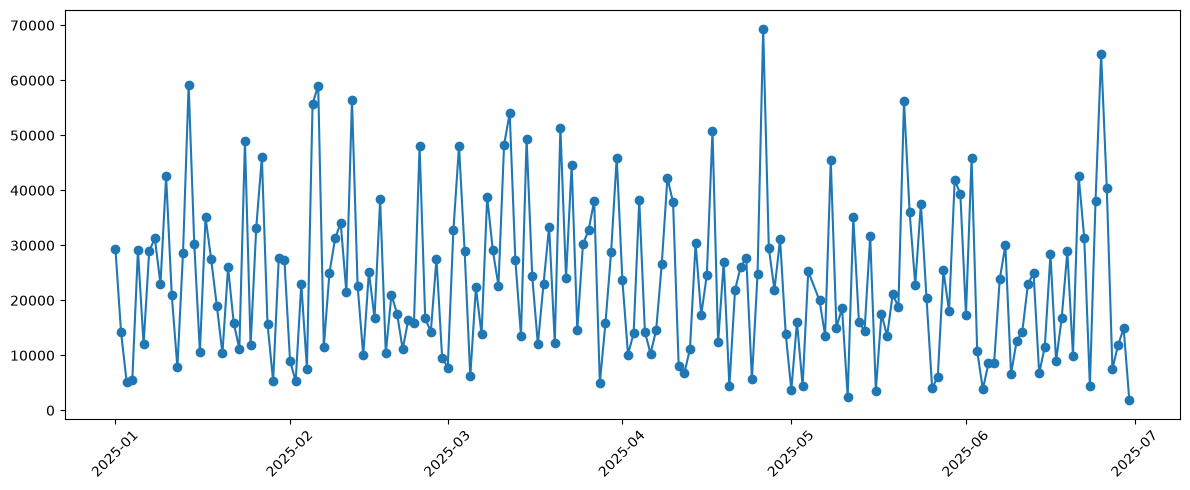

In [45]:
daily_sales = df.groupby(pd.to_datetime(df["Date"]).dt.date)["Total_Revenue"].sum().sort_index()

plt.figure(figsize=(12, 5))
plt.plot(daily_sales.index, daily_sales.values, marker="o")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

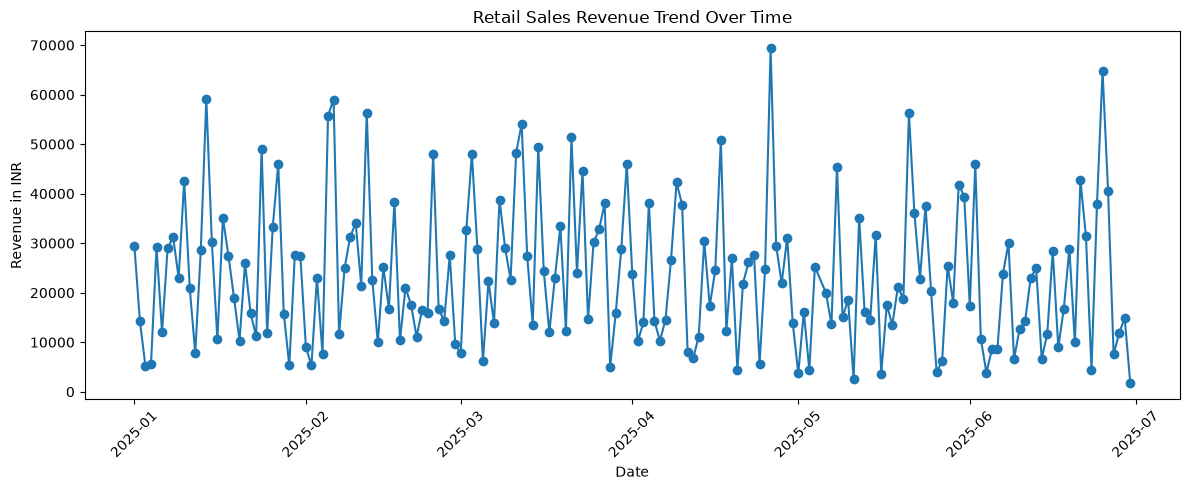

In [46]:
plt.figure(figsize=(12, 5))
plt.plot(daily_sales.index, daily_sales.values, marker="o")
plt.xlabel("Date")
plt.ylabel("Revenue in INR")
plt.title("Retail Sales Revenue Trend Over Time")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

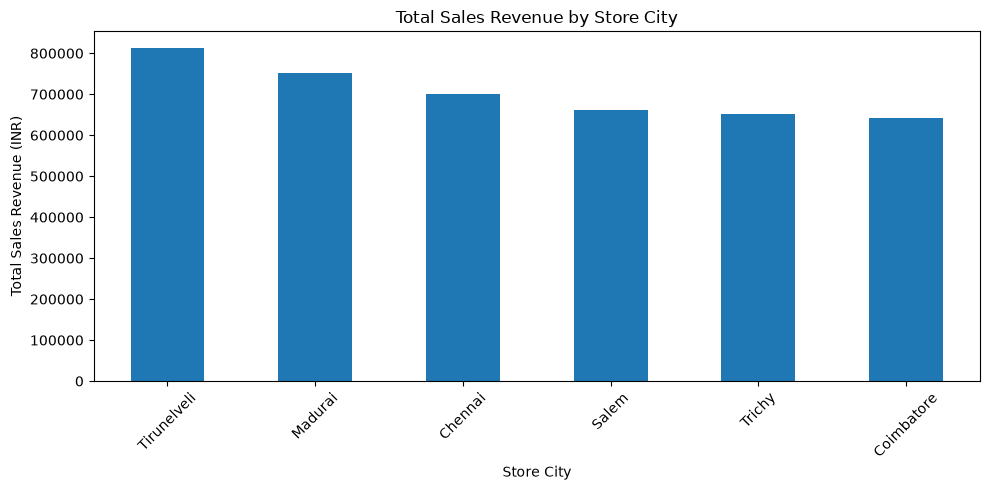

In [47]:
city_sales = df.groupby("Store_City")["Total_Revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
city_sales.plot(kind="bar")
plt.xlabel("Store City")
plt.ylabel("Total Sales Revenue (INR)")
plt.title("Total Sales Revenue by Store City")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

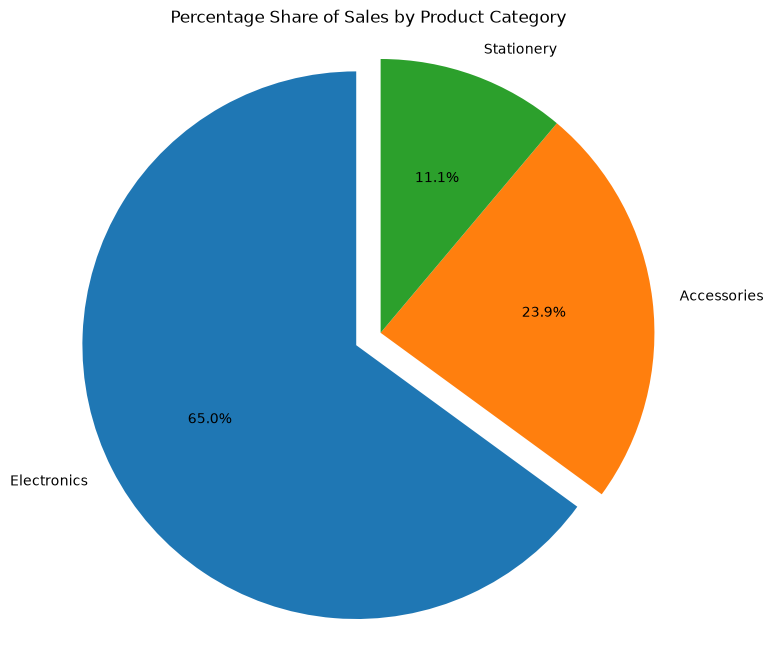

In [48]:
category_revenue = df.groupby("Category")["Total_Revenue"].sum().sort_values(ascending=False)
explode = [0.1] + [0] * (len(category_revenue) - 1)

plt.figure(figsize=(8, 8))
plt.pie(
    category_revenue,
    labels=category_revenue.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=explode
)
plt.title("Percentage Share of Sales by Product Category")
plt.axis("equal")
plt.show()

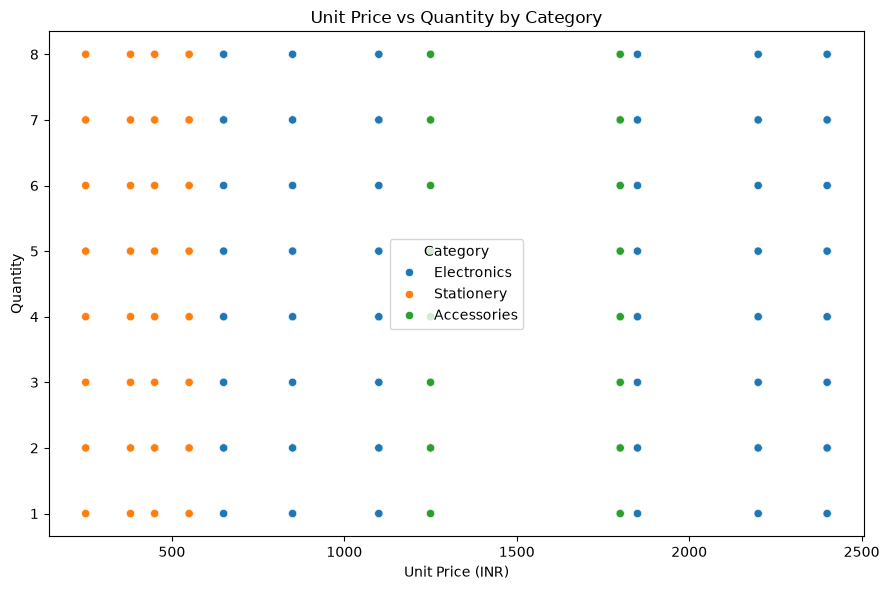

In [49]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Unit_Price",
    y="Quantity",
    hue="Category"
)
plt.title("Unit Price vs Quantity by Category")
plt.xlabel("Unit Price (INR)")
plt.ylabel("Quantity")
plt.tight_layout()
plt.show()

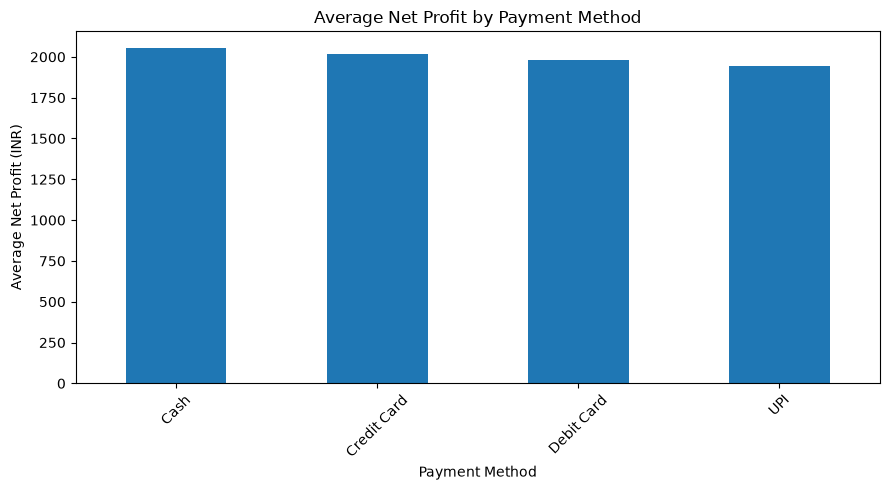

Chart saved as profit_by_payment_method.png


In [51]:
average_profit_by_payment = df.groupby("Payment_Method")["Net_Profit"].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
average_profit_by_payment.plot(kind="bar")
plt.xlabel("Payment Method")
plt.ylabel("Average Net Profit (INR)")
plt.title("Average Net Profit by Payment Method")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("profit_by_payment_method.png", dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved as profit_by_payment_method.png")